In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [112]:
from tokenize import group

df = pd.read_csv('../chat_parsed.csv')
df_info = pd.read_csv('../group_info.csv')
group_name = df_info['group_name'].iloc[0]
group_name = "Mada and Duarte"
print(group_name)

Mada and Duarte


In [89]:
df.columns

Index(['timestamp', 'date', 'time', 'sender', 'message', 'media',
       'line_number', 'datetime', 'hour', 'day_of_week', 'month', 'year'],
      dtype='object')

In [114]:
#scrollab
df.head(20)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year
0,2024-09-07 20:37:54,07/09/2024,20:37:54,Duarte,Messages and calls are end-to-end encrypted. O...,no,1,2024-09-07 20:37:54,20,Saturday,September,2024
1,2024-09-07 20:37:54,07/09/2024,20:37:54,Duarte,Duarte is a contact.,no,2,2024-09-07 20:37:54,20,Saturday,September,2024
2,2024-09-07 20:37:43,07/09/2024,20:37:43,Duarte,Madalena,no,3,2024-09-07 20:37:43,20,Saturday,September,2024
3,2024-09-07 20:37:50,07/09/2024,20:37:50,Duarte,hoje vais à festa em Lappis?,no,4,2024-09-07 20:37:50,20,Saturday,September,2024
4,2024-09-07 22:10:42,07/09/2024,22:10:42,Madalena,Nãoo nem sabia que havia ahaha,no,5,2024-09-07 22:10:42,22,Saturday,September,2024
5,2024-09-07 22:27:10,07/09/2024,22:27:10,Duarte,mas tu já estás no grupo,no,6,2024-09-07 22:27:10,22,Saturday,September,2024
6,2024-09-07 22:49:51,07/09/2024,22:49:51,Madalena,Ahhh shit não vi,no,7,2024-09-07 22:49:51,22,Saturday,September,2024
7,2024-09-07 22:50:40,07/09/2024,22:50:40,Madalena,Mas hoje não podia de qq forma,no,8,2024-09-07 22:50:40,22,Saturday,September,2024
8,2024-09-07 22:50:44,07/09/2024,22:50:44,Madalena,Vou à próxima ahah,no,9,2024-09-07 22:50:44,22,Saturday,September,2024
9,2024-09-08 00:29:19,08/09/2024,00:29:19,Duarte,ah ok tranquilo,no,10,2024-09-08 00:29:19,0,Sunday,September,2024


In [115]:
df['sender'].unique()

array(['Duarte', 'Madalena'], dtype=object)

## 0. Feature Engineering

In [116]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['year'] = df['timestamp'].dt.year
df['hour'] = df['timestamp'].dt.hour
# ensure timestamp column is in datetime format
#coerce: Converts invalid values to NaT and continues
#raise: Raises an error for invalid values
#ignore: Ignores invalid values
df['day'] = df['timestamp'].dt.day_name()
df['accumulated_messages'] = df.groupby('sender')['message'].cumcount() + 1


In [64]:
df.head(5)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year,day,accumulated_messages
0,2021-09-03 22:42:08,03/09/21,22:42:08,Alexandre Reis,Malta temos de decidir pa onde é q vamos e com...,no,3,2021-09-03 22:42:08,22,Friday,September,2021,Friday,1
1,2021-09-04 06:04:12,04/09/21,06:04:12,Duarte Morais,Por mim espanha. Mas podemos ir a outro lado,no,4,2021-09-04 06:04:12,6,Saturday,September,2021,Saturday,1
2,2021-09-04 12:16:23,04/09/21,12:16:23,Max Técnico,Eu tmb acho Espanha bacano,no,5,2021-09-04 12:16:23,12,Saturday,September,2021,Saturday,1
3,2021-09-04 12:16:47,04/09/21,12:16:47,Max Técnico,Mas eu Espanha há imensa coisa,no,6,2021-09-04 12:16:47,12,Saturday,September,2021,Saturday,2
4,2021-09-04 12:16:49,04/09/21,12:16:49,Max Técnico,Sevilha,no,7,2021-09-04 12:16:49,12,Saturday,September,2021,Saturday,3


## 1.Temporal analysis

    hour    sender  message_count
0      0    Duarte           1474
1      0  Madalena           1493
2      1    Duarte            974
3      1  Madalena           1079
4      2    Duarte            710
5      2  Madalena            839
6      3    Duarte             56
7      3  Madalena             48
8      4    Duarte             38
9      4  Madalena             53
10     5    Duarte             23
11     5  Madalena             15
12     6    Duarte             33
13     6  Madalena             26
14     7    Duarte            117
15     7  Madalena            156
16     8    Duarte            392
17     8  Madalena            434
18     9    Duarte            645
19     9  Madalena            711
20    10    Duarte            832
21    10  Madalena            843
22    11    Duarte           1189
23    11  Madalena           1326
24    12    Duarte           1272
25    12  Madalena           1454
26    13    Duarte           1480
27    13  Madalena           1663
28    14    Du

Text(0, 0.5, 'Number of Messages')

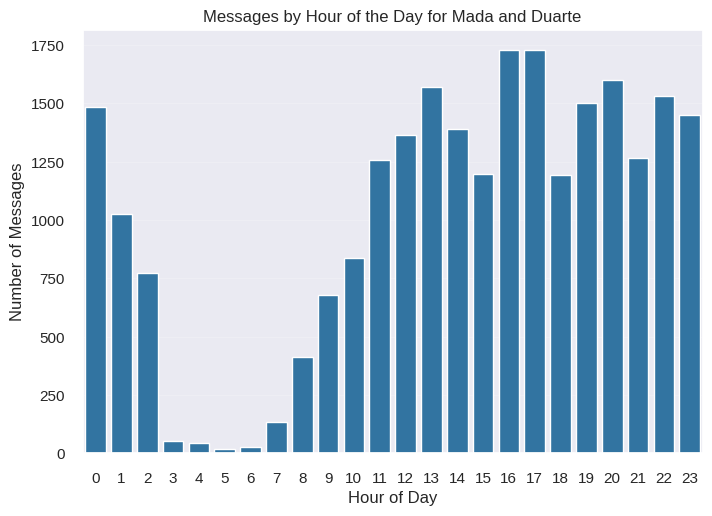

In [117]:
# plot message frequency by hour
#df['hour'].value_counts().sort_index().plot(kind='bar', color='steelblue')
hourly_counts = df.groupby(['hour', 'sender']).size().reset_index(name='message_count')
print(hourly_counts)
sns.barplot(data=hourly_counts, x='hour', y='message_count', errorbar=None)
plt.style.use('seaborn-v0_8')
plt.title(f'Messages by Hour of the Day for {group_name}')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Messages')


### Average activity during a week

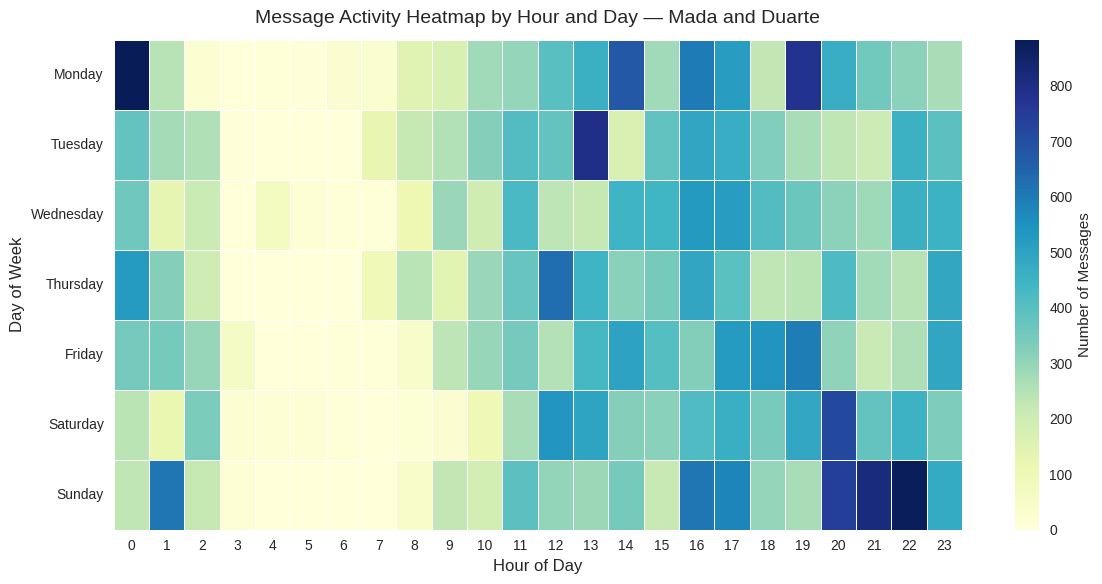

In [118]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# group by day and hour
heatmap_data = df.groupby(['day', 'hour']).size().unstack(fill_value=0)

# reorder days for better readability
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(days_order)

# plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', 
    linewidths=0.5, linecolor='white', 
    cbar_kws={'label': 'Number of Messages'}
)
plt.title(f'Message Activity Heatmap by Hour and Day — {group_name}', fontsize=14, pad=12)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Participation Analysis

### Typical content of message by user

/tmp/ipykernel_1256/1139393383.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')


   sender media  timestamp  message_count
0  Duarte    no 2024-09-30             32
1  Duarte    no 2024-10-31            584
2  Duarte    no 2024-11-30           1834
3  Duarte    no 2024-12-31           2100
4  Duarte    no 2025-01-31           2614


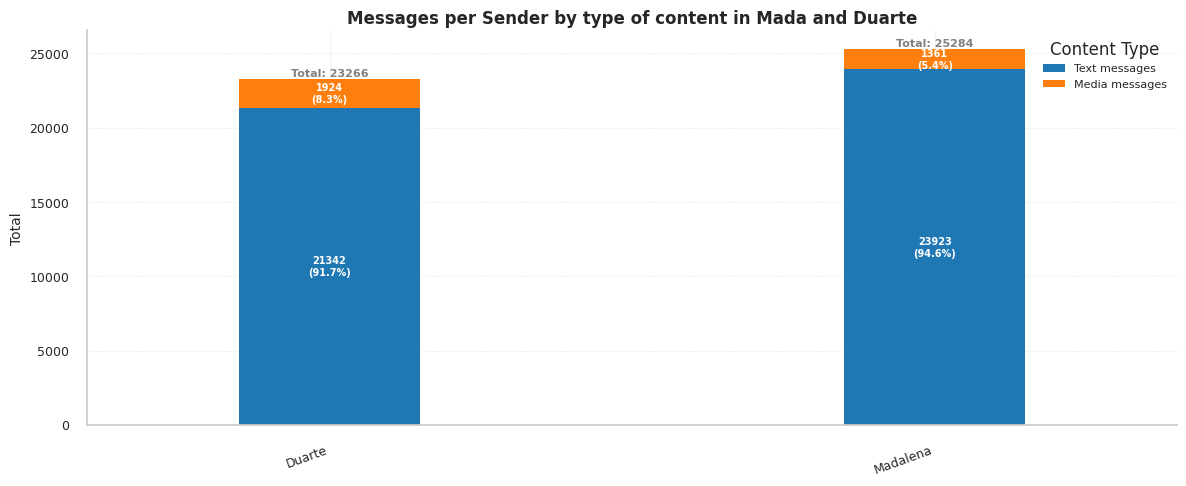

In [119]:
message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')
print(message_count.head())
pivot = (
    message_count
    .groupby(['sender', 'media'])['message_count']
    .sum()
    .unstack(fill_value=0)
)

# --- Compact plot style ---
sns.set_theme(style="whitegrid")
colors = ["#1f77b4", "#ff7f0e"]  # blue and orange

fig, ax = plt.subplots(figsize=(12, 5))
pivot.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors,
    width=0.3,
    edgecolor='none'
)

# --- Compact aesthetics ---
ax.set_title("Messages per Sender by type of content in {}".format(group_name), fontsize=12, fontweight="bold", pad=5)
ax.set_xlabel("")
ax.set_ylabel("Total", fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)
ax.tick_params(axis='y', labelsize=9)

# Minimal grid and borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.6)

# --- Annotate individual values and percentages ---
totals = pivot.sum(axis=1)
for i, (sender, row) in enumerate(pivot.iterrows()):
    total = row.sum()
    
    # Calculate percentages
    no_pct = (row.get('no', 0) / total * 100) if total > 0 else 0
    yes_pct = (row.get('yes', 0) / total * 100) if total > 0 else 0
    
    # Get individual values
    no_count = row.get('no', 0)
    yes_count = row.get('yes', 0)
    
    # Annotate "no" (regular messages) - bottom of stack
    if no_count > 0:
        ax.text(i, no_count/2, f"{int(no_count)}\n({no_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate "yes" (media messages) - top of stack
    if yes_count > 0:
        ax.text(i, no_count + yes_count/2, f"{int(yes_count)}\n({yes_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate total at the top
    ax.text(i, total + 30, f"Total: {int(total)}", ha='center', va='bottom', 
            fontsize=8, color='gray', fontweight='bold')

# --- Legend ---
ax.legend(title="Content Type", fontsize=8, loc='upper right', frameon=False)

# Update legend labels
legend = ax.get_legend()
if legend:
    legend.get_texts()[0].set_text('Text messages')  # Changes 'no' to 'Text messages'
    legend.get_texts()[1].set_text('Media messages')  # Changes 'yes' to 'Media messages'


plt.tight_layout(pad=1)
plt.show()



### Boxplots (Top view of dist.)

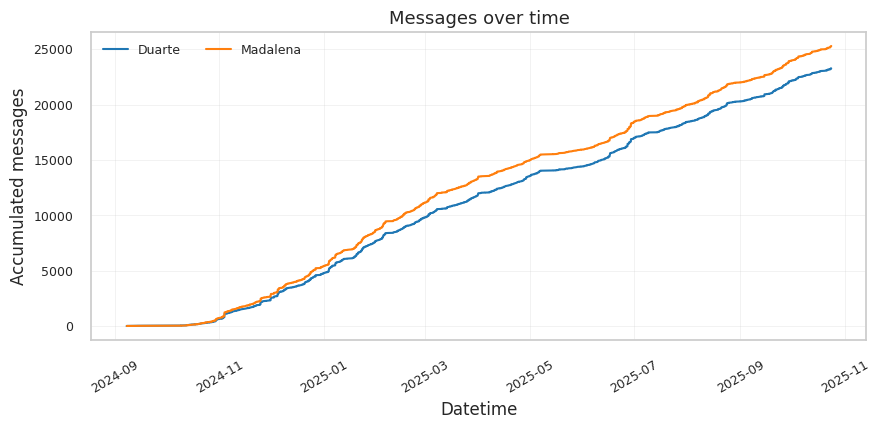

In [120]:
sns.set_palette("tab10")  # or try "tab10", "colorblind", "Dark2"
fig, ax = plt.subplots(figsize=(10, 4))
df['timestamp_'] = pd.to_datetime(df['timestamp'][1:])
sns.lineplot(data=df, x="timestamp_", y="accumulated_messages", hue="sender")
plt.title("Messages over time", fontsize=13)
plt.xlabel("Datetime")
plt.ylabel("Accumulated messages")
# Compact tick formatting
plt.xticks(rotation=30, fontsize=9)
plt.yticks(fontsize=9)
plt.grid(True, alpha=0.3, linewidth=0.6)
#more space between the lines
# Compact legend
plt.legend(
    title=None,
    fontsize=9,
    loc="upper left",
    frameon=False,
    ncol=2  # 2-column legend to save space
)
plt.show()

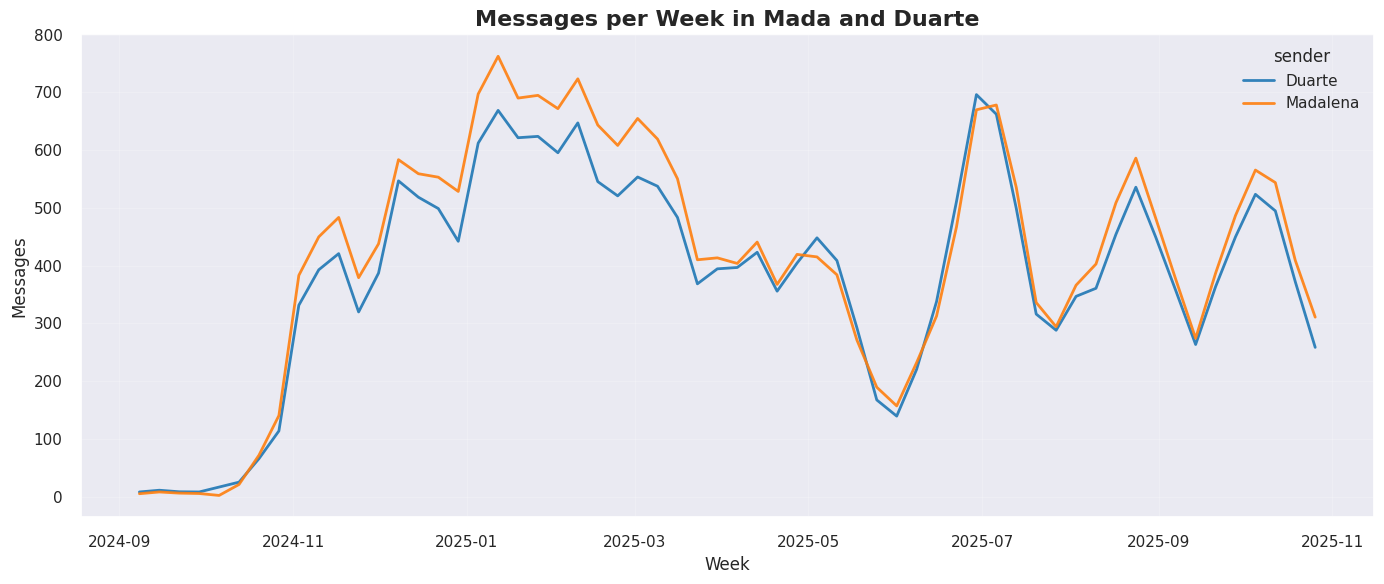

       sender       date  messages_per_week  messages_smooth
101  Madalena 2025-06-29                950       669.666667
79   Madalena 2025-01-26                921       694.666667
76   Madalena 2025-01-05                907       697.000000
41     Duarte 2025-06-29                904       696.000000
19     Duarte 2025-01-26                847       623.666667


In [121]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure 'date' is a datetime
#df['date'] = pd.to_datetime(df['date'])
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

# --- Aggregate per sender per week ---
weekly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='W')])
    .size()
    .reset_index(name='messages_per_week')
)

# --- 3-week moving average for smoother trends ---
weekly_counts['messages_smooth'] = (
    weekly_counts.groupby('sender')['messages_per_week']
    .transform(lambda x: x.rolling(3, min_periods=1).mean())
)

# --- Plot ---
plt.style.use("dark_background")
sns.set_theme(style="darkgrid", palette="tab10")

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=weekly_counts,
    x="date",
    y="messages_smooth",
    hue="sender",
    linewidth=2.0,
    alpha=0.9
)

plt.title(f"Messages per Week in {group_name}", fontsize=16, fontweight='bold')
plt.xlabel("Week")
plt.ylabel("Messages")
plt.tight_layout()
plt.show()

# --- Optional: top 5 busiest weeks ---
print(
    weekly_counts.sort_values(by='messages_per_week', ascending=False)
    .head(5)
)


In [76]:
#i want to find the top five senders with the most messages in one day which I dont know the date
#so I need to find the top five senders with the most messages in one day
#I can do this by grouping by sender and date and then counting the number of messages
#and then sorting by the number of messages
#and then getting the top five
df.groupby(['sender', 'date']).size().sort_values(ascending=False).head(5)


sender       date      
João Dias    2023-01-24    135
             2022-05-05    127
             2022-02-11    108
Max Técnico  2022-05-05    104
João Dias    2022-02-15    104
dtype: int64

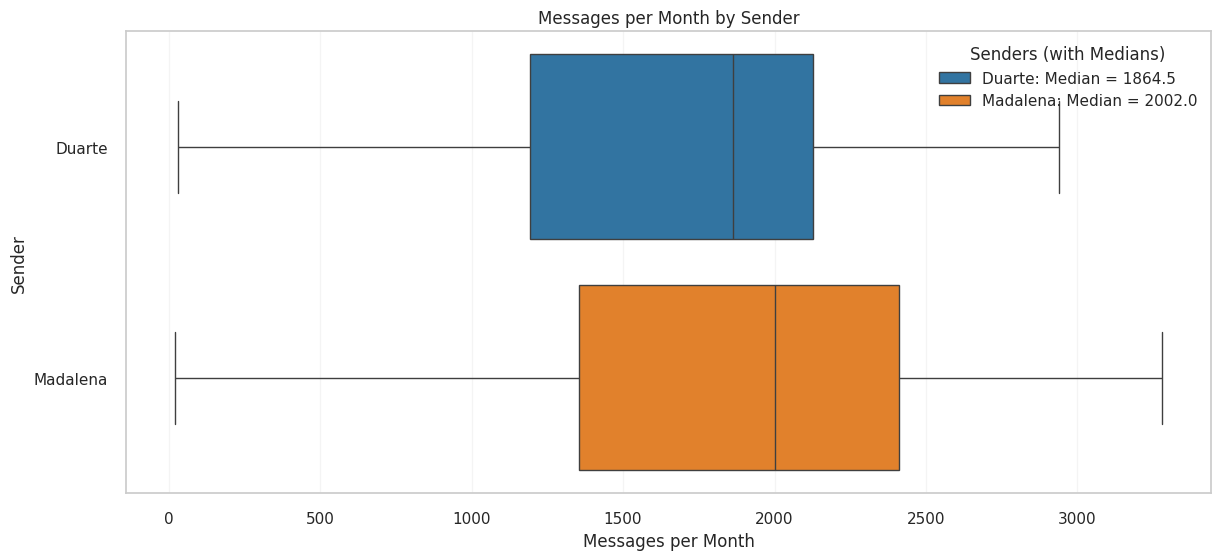

In [122]:
# Ensure 'date' is datetime
df['date'] = pd.to_datetime(df['date'])

# --- Aggregate per sender per month ---
monthly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='ME')])
    .size()
    .reset_index(name='messages_per_month')
)
# --- Plot grouped bar chart ---
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid", palette="tab10")
# Calculate medians for each sender
medians = monthly_counts.groupby('sender')['messages_per_month'].median()
# Create legend with median values


sns.boxplot(data=monthly_counts,
    x="messages_per_month",
    y="sender",
    hue="sender"
)

legend_labels = [f"{sender}: Median = {median:.1f}" for sender, median in medians.items()]
plt.legend(legend_labels, title="Senders (with Medians)", loc='upper right', bbox_to_anchor=(1.0, 1.0))
plt.title("Messages per Month by Sender")
plt.xlabel("Messages per Month")
plt.ylabel("Sender")
plt.show()

### Barplot

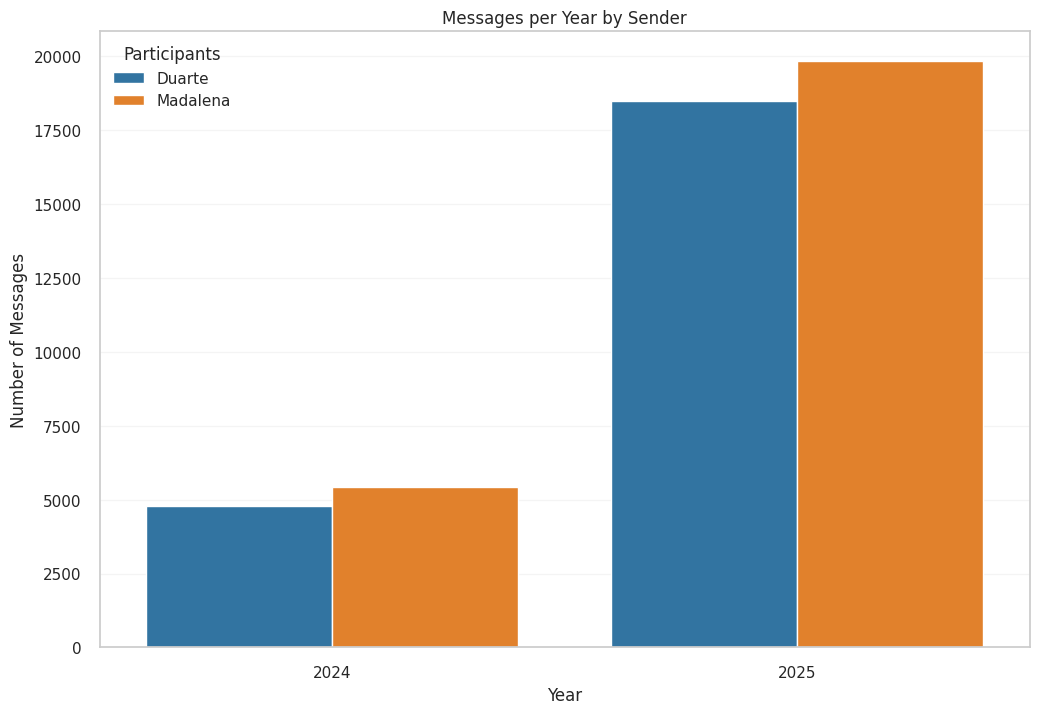

In [123]:
# Create yearly message counts
yearly_messages = df.groupby(['year', 'sender']).size().reset_index(name='message_count')

# Stacked bar chart by year
plt.figure(figsize=(12, 8))
sns.barplot(data=yearly_messages, x='year', y='message_count', hue='sender')
plt.title('Messages per Year by Sender')
plt.xlabel('Year')
plt.ylabel('Number of Messages')
plt.legend(title='Participants')
plt.show()

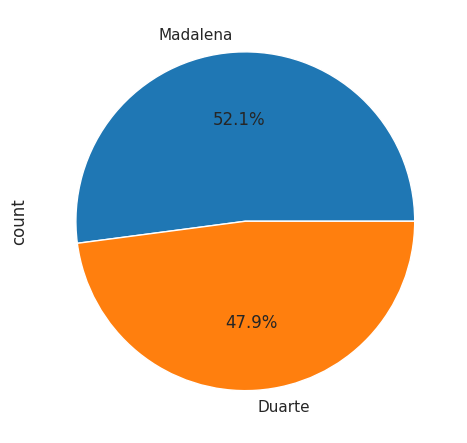

In [124]:
#seaborn pie chart
df['sender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.show()


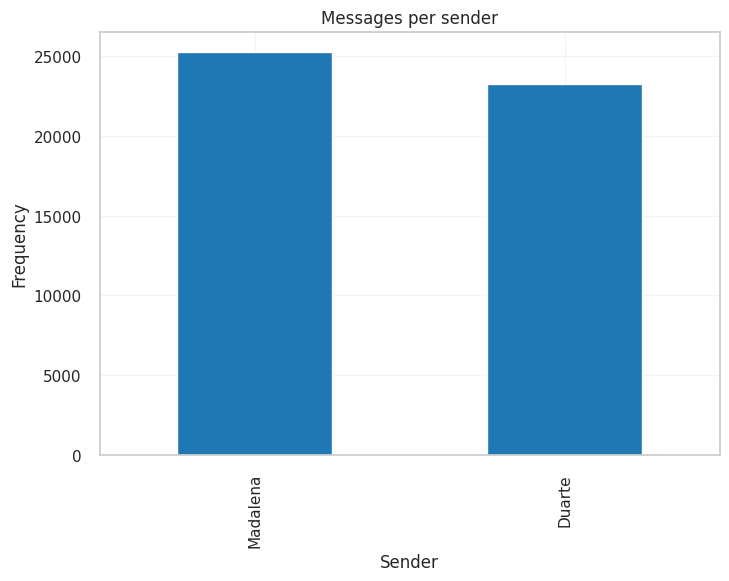

sender
Madalena    52.08
Duarte      47.92
Name: proportion, dtype: float64

In [125]:
#percentage of messages per sender
df['sender'].value_counts(normalize=True)

#total messages per sender
df['sender'].value_counts()

#in a bar plot
ax = df['sender'].value_counts().plot(kind='bar') 
ax.set_title('Messages per sender')
ax.set_xlabel('Sender')
ax.set_ylabel('Frequency')
plt.show()

(df['sender'].value_counts(normalize=True) * 100).round(2)


# Sentiment Analysis

In [126]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ensure datetime and hour columns are correct
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['date'] = df['timestamp'].dt.date

# Filter out media messages
df_text = df[df['media'] == 'no'].copy()

# ✅ Only include senders with more than 5 messages
sender_counts = df_text['sender'].value_counts()
valid_senders = sender_counts[sender_counts > 5].index
df_filtered = df_text[df_text['sender'].isin(valid_senders)]

# Define color palette by sender
senders = df_filtered['sender'].unique()
palette = sns.color_palette("husl", len(senders))

sns.set_theme(style="whitegrid", font_scale=1.15, rc={
    "axes.edgecolor": "0.2",
    "axes.linewidth": 1.2,
    "grid.alpha": 0.2
})

# Main plot using relplot (auto-handles facets & legends)
g = sns.relplot(
    data=df_filtered,
    x="hour",
    y="message_length",
    hue="sender",
    size="word_count",
    sizes=(20, 200),
    alpha=0.70,
    palette=palette,
    col="sender",
    col_wrap=3,
    kind="scatter",
    height=3.8,
    aspect=1.2,
)

# KDE contours for each sender (for density visualization)
for ax, sender in zip(g.axes.flatten(), senders):
    sns.kdeplot(
        data=df_filtered[df_filtered['sender'] == sender],
        x="hour",
        y="message_length",
        fill=True,
        alpha=0.18,
        levels=5,
        ax=ax,
        color=palette[list(senders).index(sender)]
    )

# Improve readability
g.set_titles("{col_name}", fontweight="bold", fontsize=11)
g.set_axis_labels("Hour of Day", "Message Length (chars)")
g.set(xlim=(-0.4, 24))
for ax in g.axes.flatten():
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.set_facecolor("#fafafa")

# Global title
plt.subplots_adjust(top=0.9, hspace=0.3)
g.fig.suptitle("Messaging Behavior per Sender)", 
               fontsize=16, weight="bold")

# Adjust legend position and title
g._legend.set_bbox_to_anchor((1.02, 0.5))
g._legend.set_title("Sender")

plt.show()


ValueError: Could not interpret value `message_length` for `y`. An entry with this name does not appear in `data`.

In [127]:
#average menssage lenght
df['message_length'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['average_word_length'] = df['message_length'] / df['word_count']
df.groupby('sender')[['message_length', 'word_count', 'average_word_length']].mean()

,message_length,word_count,average_word_length
sender,,,
Duarte,26.159632,5.219978,5.19452
Madalena,26.677345,5.326926,5.23360


   gap_flag  gap_minutes           timestamp
0        no          NaN 2024-09-07 20:37:54
1       yes     0.000000 2024-09-07 20:37:54
2       yes    -0.183333 2024-09-07 20:37:43
3       yes     0.116667 2024-09-07 20:37:50
4        no    92.866667 2024-09-07 22:10:42
5        no    16.466667 2024-09-07 22:27:10
6        no    22.683333 2024-09-07 22:49:51
7       yes     0.816667 2024-09-07 22:50:40
8       yes     0.066667 2024-09-07 22:50:44
9        no    98.583333 2024-09-08 00:29:19
10      yes     0.400000 2024-09-08 00:29:43
11      yes     0.766667 2024-09-08 00:30:29
12       no   923.166667 2024-09-08 15:53:39
13       no  2933.550000 2024-09-10 16:47:12
14      yes     0.733333 2024-09-10 16:47:56
15      yes     0.250000 2024-09-10 16:48:11
16       no  1106.616667 2024-09-11 11:14:48
17       no    88.400000 2024-09-11 12:43:12
18      yes     0.850000 2024-09-11 12:44:03
19      yes     0.633333 2024-09-11 12:44:41


<Axes: xlabel='year', ylabel='gap_minutes'>

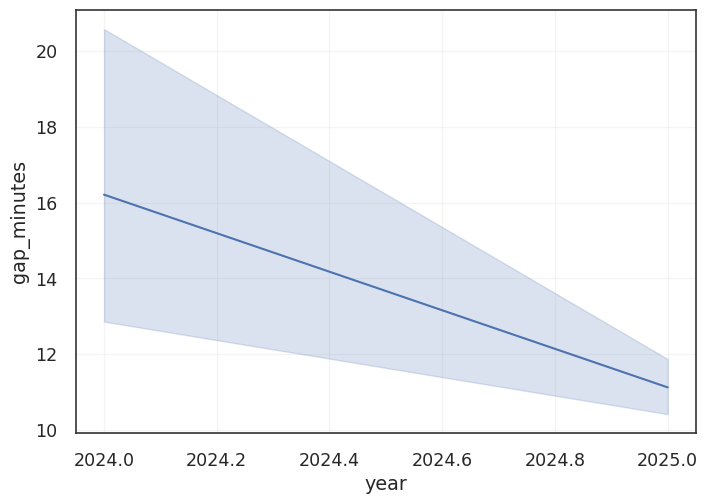

In [128]:
df['time_gap'] = df['timestamp'].diff()
df['gap_seconds'] = df['time_gap'].dt.total_seconds()
df['gap_minutes'] = df['gap_seconds'] / 60

#I want to mark as yes if the gap is less than 5 minutes for N messages in a row
#and have to be more than 10 messages in a row to all get the flag as yes
df['gap_flag'] = df['gap_minutes'].apply(lambda x: 'yes' if x < 2 else 'no')

# Remove first row (NaN) and filter out negative gaps (data issues)
gaps = df['gap_seconds'].dropna()
gaps = gaps[gaps >= 0]  # Remove any negative gaps

print(df[["gap_flag", "gap_minutes", "timestamp"]][0:20])

sns.lineplot(data=df, x="year", y="gap_minutes")


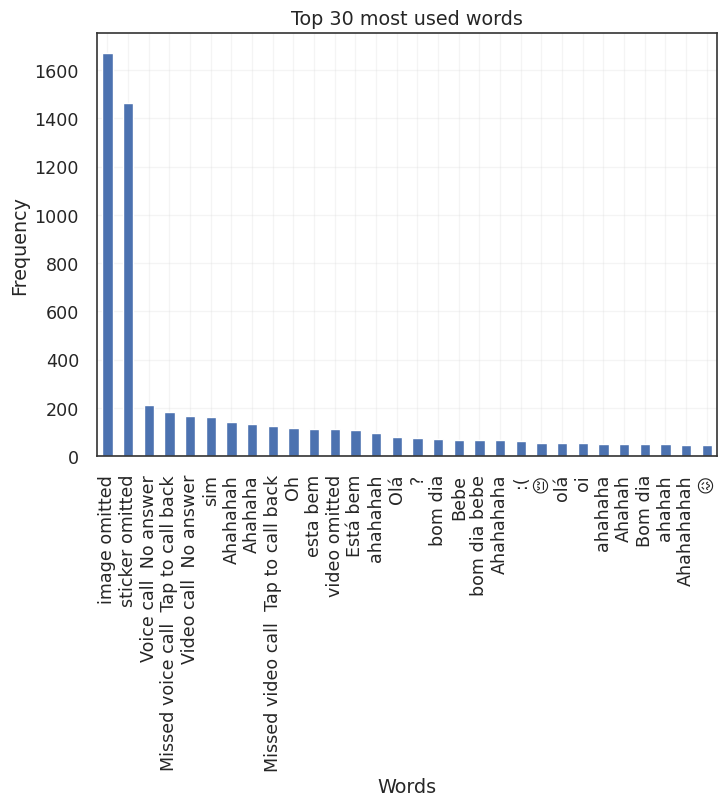

In [132]:
#top most used words
#top most used words
ax = df['message'].value_counts().head(30).plot(kind='bar')
ax.set_title('Top 30 most used words')
ax.set_xlabel('Words')
ax.set_ylabel('Frequency')
plt.show()


In [130]:
import nltk
nltk.download('stopwords')  # Download stopwords data first
from nltk.corpus import stopwords
stopwords = set(stopwords.words('portuguese'))
stopwords.update(['imagem', 'video', 'revelada', 'não', 'Não', 'revelado'])
import re
from collections import Counter

# Get all words
all_words = re.findall(r'\b\w+\b', ' '.join(df['message'].astype(str)).lower())

# Words with only 2 different letters
def has_only_two_unique_letters(word):
    """Check if a word has only 2 unique letters."""
    unique_letters = set(word.lower())
    return len(unique_letters) == 2


# Filter words with only 2 unique letters
for word in all_words:
    word = word.lower()
two_letter_words = [word for word in all_words if has_only_two_unique_letters(word) and len(word) > 2]
print("Words with only 2 different letters:", Counter(two_letter_words).most_common(10))

stopwords.update(two_letter_words)

# Split all sender names and add individual words
all_sender_words = ' '.join(df['sender'].unique()).split()
stopwords.update(all_sender_words)

#except the last one
senders = df['sender'].unique()[1:]
for sender in senders:
    sender_messages = df[df['sender'] == sender]
    all_words = ' '.join(sender_messages['message']).split()
    
    # Calculate word frequencies
    word_freq = {}
    for word in all_words:
        word_freq[word] = word_freq.get(word, 0) + 1
    
    # Sort words by frequency in descending order
    sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
    #filter out words with less than 2 letters
    sorted_words = [word for word in sorted_words if len(word[0]) >= 4]
    #filter out words that are in the stopwords list
    sorted_words = [word for word in sorted_words if word[0] not in stopwords]

    # Get top 5 most distinctive words
    top_words = sorted_words[:5]
    
    # Print results
    print(f"Top 5 most distinctive words for {sender}:")

    # Print top 5 words with their frequencies
    for word, freq in top_words:
        print(f"{word}: {freq}")
    print("\n")



[nltk_data] Downloading package stopwords to
[nltk_data]     /home/duarte33/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Words with only 2 different letters: [('bebe', 946), ('ahahah', 625), ('ele', 598), ('ahahaha', 456), ('ahahahah', 357), ('ahaha', 331), ('fofo', 239), ('mim', 206), ('esse', 181), ('ahh', 99)]
Top 5 most distinctive words for Madalena:
omitted: 1402
call: 715
sticker: 685
image: 622
Voice: 381


